#### GECC 4130 Exploratory Data Analysis
This notebook aims to discover the relationships within the temp_ and verify our assumptions based on daily observation.

##### Road Map

|Steps|Proprocedure|Description|
| --- | --- | --- |
|S1 |Data Cleaning Pre-processing |Transform and combine irregular messy data into a structured time interval|
|S2 |Data Visualization |Display data by week and semester|
|S3 |Hypothesis Test | Distribution test with different time interval and distribution type test|
|S4 |Correlation Analysis|Explore the correlation between data and features|


In [1]:
#S1 Data Pre-processing

"""
We collects data from 2 entries and 1 exit of Chung Chi Library. 
The first step is to combine two entries data into single data series.
"""

GRAPH_URL = r"C:\Users\antho\文件\VS Code\python proj\GECC_Data_Analysis\graph"

import pandas as pd

def load_data(file_path, file_type):
    if file_type == "csv":
        return pd.read_csv(file_path)
    elif file_type in ("xlsx", "xlsm"):
        return pd.read_excel(file_path, engine='openpyxl')
    elif file_type == "xls":
        return pd.read_excel(file_path, engine='xlrd')
    else:
        raise ValueError(f"Unsupported file type: {file_type}")

path_collections = {
    "occupancy_data": ("16wm1QzRbMRTElnQz_P-Q0gZH52r87HZU", "csv"),
    "history_entries1_data": ("1rtVwYkoehdQyRqt_NKG6WuNaraonspJf", "xls"),
    "history_entries2_data": ("17ufg4NXUUh_Yb7hFd_K5hq1iHbdW_V7K", "xls"),
}

for key, (file_id, file_type) in path_collections.items():
    url = f"https://drive.google.com/uc?export=download&id={file_id}"
    globals()[key] = load_data(url, file_type)


C:\Users\antho\AppData\Local\Temp\ipykernel_4168\198565546.py:18: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  return pd.read_excel(file_path, engine='xlrd')
C:\Users\antho\AppData\Local\Temp\ipykernel_4168\198565546.py:18: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  return pd.read_excel(file_path, engine='xlrd')


In [2]:
print(occupancy_data.head())          
print(history_entries1_data.head())
print(history_entries2_data.head())   

           recorded_at  occupant_change  occupant_count
0  2026-09-19_17:53:30               -1             329
1  2026-09-19_17:53:33                1             330
2  2026-09-19_17:53:52                1             331
3  2026-09-19_17:54:34                1             332
4  2026-09-19_17:55:25               -1             331
          Report Date: 2026-06-30 00:00:00
0          Controller:     CC_01 Turnstile
1  2025-06-30 09:03:42                  In
2  2025-06-30 09:08:48                  In
3  2025-06-30 09:09:07                  In
4  2025-06-30 09:09:39                  In
          Report Date: 2026-06-30 00:00:00
0          Controller:    CC_02  Turnstile
1  2025-06-30 07:54:59                  In
2  2025-06-30 08:59:16                  In
3  2025-06-30 08:59:24                  In
4  2025-06-30 08:59:35                  In


In [3]:
import data_processing_func as dpf
# Historical Data Processing

history_entries1_data.columns = ("Time","Type_Entry")
history_entries2_data.columns = ("Time","Type_Entry")

# remove frist row which is old title
history_entries1_data = history_entries1_data.iloc[1:].reset_index(drop=True)
history_entries2_data = history_entries2_data.iloc[1:].reset_index(drop=True)

data = pd.merge(history_entries1_data,history_entries2_data, on= "Time",how='outer')
data.head(5)
print(f" data_x1 categories: {set(data['Type_Entry_x'])} \n data_x2 categories: {set(data['Type_Entry_y'])}")
data = data[(data["Type_Entry_x"] != "Invalid Card ID [In]") & (data["Type_Entry_y"] != "Invalid Card ID [In]")]

mapping={
    "In": 1,
    "Release Pressed": 1
}

data["mash_x"] = data["Type_Entry_x"].map(mapping)
data["mash_y"] = data["Type_Entry_y"].map(mapping)
data["entry_count"] = data[['mash_x', 'mash_y']].sum(axis=1)

data.set_index('Time', inplace=True)

data_ts = pd.DataFrame(index=data.index, data= data['entry_count'])
data_ts = data_ts.groupby('Time', as_index=True).sum()

#===============================================================================
# output
data_ts.head(5)
data_ts.index = pd.to_datetime(data_ts.index)
data_ts_h = data_ts.resample('1h').sum()
data_ts_h = data_ts_h.between_time('08:20', '22:00')

historial_y, historial_x = data_ts_h, dpf._features(data_ts_h,overrides={})

 data_x1 categories: {'In', nan, 'Release Pressed', 'Invalid Card ID [In]'} 
 data_x2 categories: {'In', nan, 'Release Pressed', 'Invalid Card ID [In]'}


C:\Users\antho\AppData\Local\Temp\ipykernel_4168\1038945988.py:25: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.set_index('Time', inplace=True)


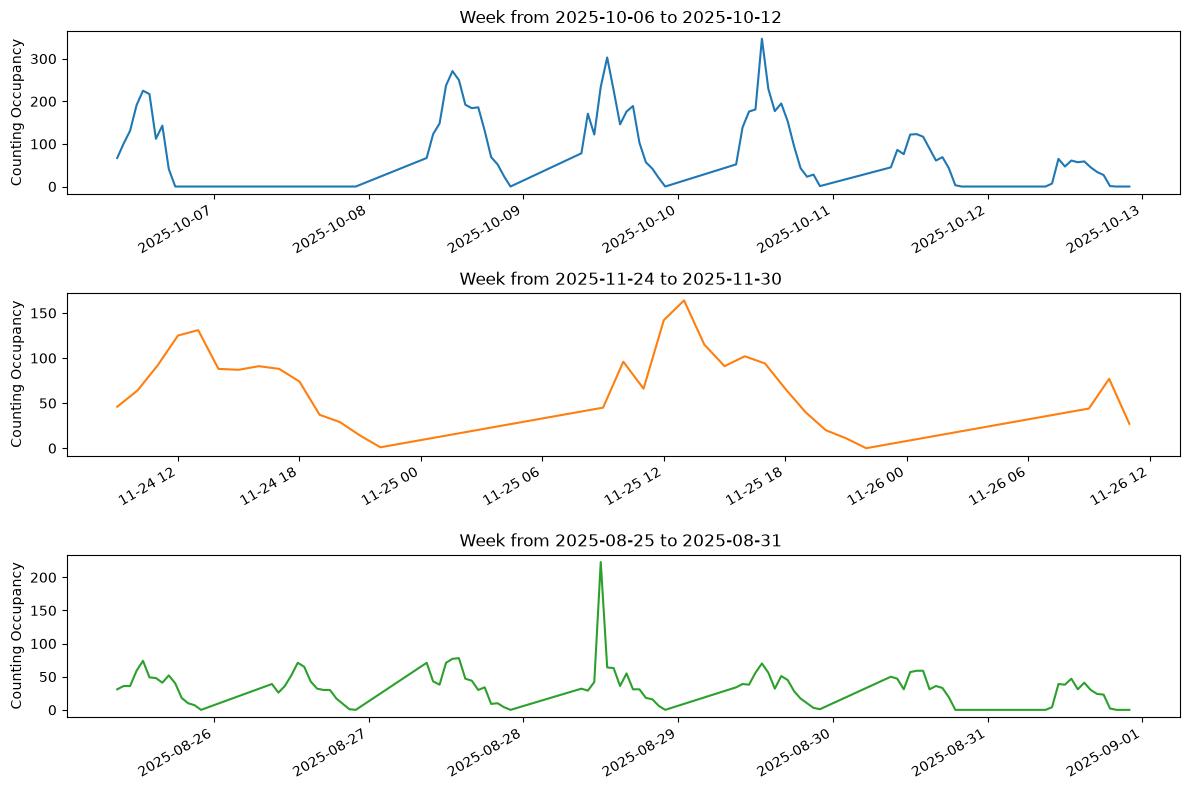

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import os
unique_weeks = historial_y.index.to_period("W").unique()
sampled_weeks = np.random.choice(unique_weeks, 3, replace=False)

# Choose 3 distinct colors
colors = ['tab:blue', 'tab:orange', 'tab:green']

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=False)

for ax, week_period, color in zip(axes, sampled_weeks, colors):
    # Mask for selected week
    mask = historial_y.index.to_period("W") == week_period
    week_data = historial_y.loc[mask]

    # Plot raw data for the week in specified color
    week_data.plot(ax=ax, color=color, legend=False)

    ax.set_title(f"Week from {week_period.start_time.date()} to {week_period.end_time.date()} ")
    ax.set_ylabel("Counting Occupancy")
    ax.set_xlabel(None)


plt.tight_layout()
plt.savefig(os.path.join(GRAPH_URL, "3_weeks_plot.png")
            )
plt.show()


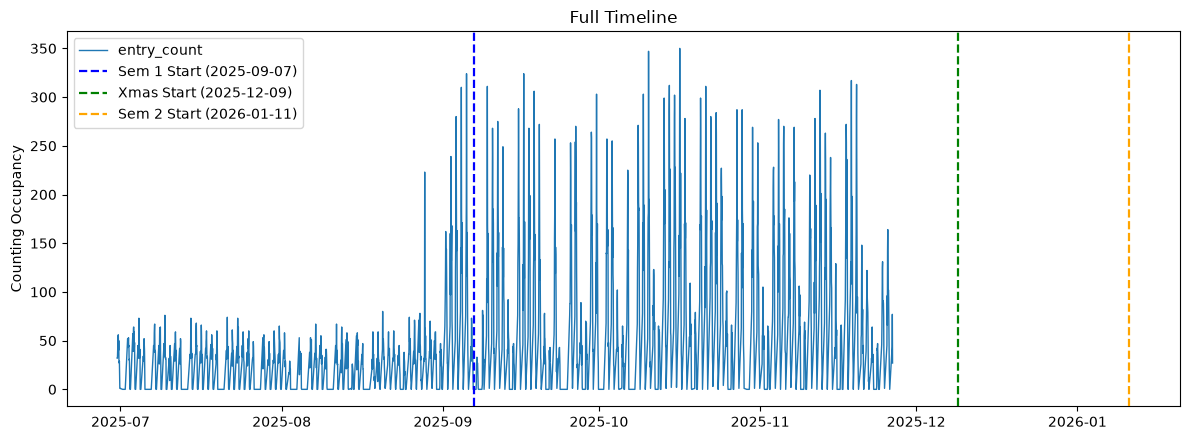

In [5]:
import matplotlib.pyplot as plt

thresholds = {
    "Sem 1 Start (2025-09-07)": "2025-09-07",
    "Xmas Start (2025-12-09)": "2025-12-09",
    "Sem 2 Start (2026-01-11)": "2026-01-11"
}

thresholds = {k: pd.to_datetime(v) for k, v in thresholds.items()}

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(historial_y.index, historial_y.values, color="#1f77b4", linewidth=1, label="entry_count")


colors = ["blue", "green", "orange"]
for (label, dt), color in zip(thresholds.items(), colors):
    ax.axvline(dt, color=color, linestyle="--", linewidth=1.6, label=label, zorder=3)

ax.set_ylabel("Counting Occupancy")
ax.set_title("Full Timeline")
ax.legend(loc="upper left")

plt.tight_layout()

plt.savefig(os.path.join(GRAPH_URL, "3_weeks_plot.png")
            )
plt.show()


## EDA Insight
From two graph above, there are existed obvious patterns between data. We summaries it as 4 points

#### Daily Cycle
The distribution of entry counting for each day are quite similar, which center around 12:00 to 14:00, we may assume daily data shares same distribution.

#### Weekday Cycle
Weekdays pattern is separated into two parts: one consists of school days from Monday to Friday, and the other is about regular public holidays.\
Students are more likely to study on school days rather than on weekends. Weekly graph shows the significant drop between Friday and Saturday.

#### Semester Effect
There is existed a noticeable change between summer semester and semester 1. So we may assume there also existed same pattern across summer, first and second semester.

#### Hoilday Effect
Following the regular public holiday effect mentioned above, we may assume that fewer people will go to the library during a long holiday period like the Mid-Autumn Festival.

Hence, we may form an addtive equation that connect those relationships:

$$
f(X \mid D) = \mathcal{D}_{\text{daily}} + \mathcal{D}_{\text{weekday}} + \text{Flag}_{\text{semester}} + \text{Flag}_{\text{holiday}}
$$

## Hypothesis Test

After, we form an equation about data distribution which actually contains some hidden hypothesis.

1. Indicator variables (the date of semester and holiday) are consistent time 
2. Daily, weekly variables are independent and identically distributed from their own distribution

For first condition, it is true since the date of public holiday are kind of fixed at each year, we handle this problem later with model setting if needed

For second condition, we should check the distribution of data by picking up sample pair to do muti-steps KS test


In [6]:
#Hypothesis Test
"""
Remarks:
There have some zero lists, it is becasue the library is closed like some public holidays.
Then we drop those zero lists.
"""
historial_y.index = pd.to_datetime(historial_y.index)
cleaned = historial_y.loc[historial_y['entry_count'].notna() & (historial_y['entry_count'] != 0)]

daily_series = cleaned['entry_count'].resample('D').apply(list)
daily_series = daily_series[daily_series.map(bool)]
dates = daily_series.index.normalize()
daily_lists = daily_series.tolist()

In [ ]:
from scipy.stats import ks_2samp
import numpy as np

# baseline_days
baseline_days = [daily_lists[0], daily_lists[54]]

daily_ks_results = []   # list of lists: one inner list per baseline
daily_pvals = []        # list of lists of p-values, aligned with daily_lists[1:]

for baseline in baseline_days:
    pvals_temp = []
    ks_result_temp = []
    for i, day in enumerate(daily_lists[1:]):  
        if len(day) == 0 or len(baseline) == 0:
            stat, p = np.nan, np.nan
        else:
            stat, p = ks_2samp(day, baseline)  
        ks_result_temp.append((i, stat, p))
        pvals_temp.append(p)

    daily_ks_results.append(ks_result_temp)
    daily_pvals.append(pvals_temp)


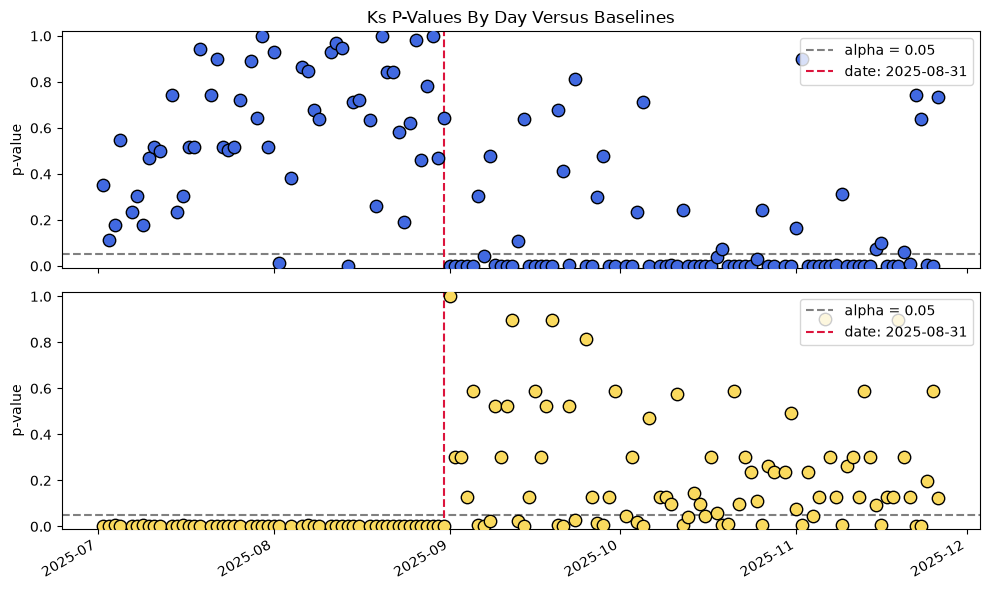

In [8]:

import matplotlib.dates as mdates

x = dates[1:]

fig, (ax1, ax2) = plt.subplots(nrows=2, figsize=(10, 6), sharex=True)

# --- first baseline---
ax1.scatter(x, daily_pvals[0], s=80, color='royalblue', edgecolors='black', zorder=3)
ax1.axhline(0.05, color='gray', linestyle='--', label='alpha = 0.05')

ax1.axvline(dates[53], color='crimson', linestyle='--', linewidth=1.5,
            label=f'date: {dates[53].strftime("%Y-%m-%d")}')
ax1.set_ylabel('p-value')
ax1.set_ylim(-0.01, 1.02)
ax1.set_title('KS p-values by day versus baseline (2025-06-30)'.title())
ax1.legend(loc='upper right')

# --- second baseline ---
ax2.scatter(x, daily_pvals[1], s=80, color='#FADA5E', edgecolors='black', zorder=3)
ax2.axhline(0.05, color='gray', linestyle='--', label='alpha = 0.05')
ax2.axvline(dates[53], color='crimson', linestyle='--', linewidth=1.5,
            label=f'date: {dates[53].strftime("%Y-%m-%d")}')
ax2.set_ylabel('p-value')
ax2.set_ylim(-0.01, 1.02)
ax2.legend(loc='upper right')
ax1.set_title('KS p-values by day versus baselines'.title())


#ax2.xaxis.set_major_locator(mdates.AutoDateLocator())
#ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
fig.autofmt_xdate(rotation=30, ha='right')

plt.tight_layout()

plt.savefig(os.path.join(GRAPH_URL, "KS_P_values_sem_plot.png")
        )
plt.show()

## Hypothesis Test Result

Hypothesis:

- H0: distributions of baseline and other day is same
- H1: Otherwise

It seems like data has 2 different distributions, they are depends on 2 semesters. For Graph 1, most of the data cannot reject H0 during summer semester, which reveals they are similar. This result also appeared with Graph 2 vice versa.




##  Analysis
Currently, since we only have single variable time series, so ACF would be a great choice to explore correlation between different lagged y.

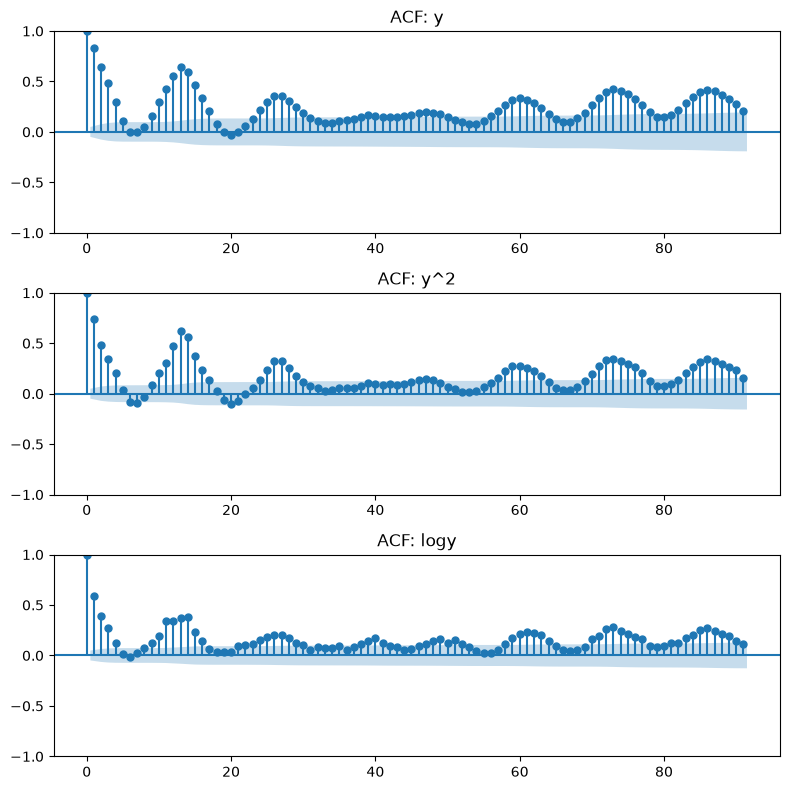

"\nnumeric ACFs (optional)\nacf_y = acf(y, nlags=nlags, fft=True, missing='drop')\nacf_y2 = acf(y2, nlags=nlags, fft=True, missing='drop')\nacf_logy = acf(logy, nlags=nlags, fft=True, missing='drop')\n\n"

In [39]:

from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import acf

# transformations
nlags = 13 * 7
y = cleaned
y2 = y ** 2
logy = np.log(y)

# plot
fig, axes = plt.subplots(3, 1, figsize=(8, 8), tight_layout=True)
plot_acf(y, ax=axes[0], lags=nlags, alpha=0.05); axes[0].set_title("ACF: y")
plot_acf(y2, ax=axes[1], lags=nlags, alpha=0.05); axes[1].set_title("ACF: y^2")
plot_acf(logy, ax=axes[2], lags=nlags, alpha=0.05); axes[2].set_title("ACF: logy")
plt.show()

"""
numeric ACFs (optional)
acf_y = acf(y, nlags=nlags, fft=True, missing='drop')
acf_y2 = acf(y2, nlags=nlags, fft=True, missing='drop')
acf_logy = acf(logy, nlags=nlags, fft=True, missing='drop')

"""